In [ ]:
!pip install -q flwr[simulation] tensorflow numpy

In [ ]:
import tensorflow as tf
import numpy as np

# 1de la b. Chargement ase de données MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalisation des pixels (de 0 à 1) et ajout de la dimension pour les filtres (canaux)
x_train, x_test = x_train / 255.0, x_test / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# 2. Séparation des données : Le cœur de la confidentialité
# Le Serveur ne verra JAMAIS ces variables.
x_train_client1, y_train_client1 = x_train[:30000], y_train[:30000]
x_train_client2, y_train_client2 = x_train[30000:], y_train[30000:]

print(f"Base Globale (Centralisée) : {len(x_train)} images")
print(f"Données Client 1 : {len(x_train_client1)} images privées, invisibles pour le serveur.")
print(f"Données Client 2 : {len(x_train_client2)} images privées, invisibles pour le serveur.")

Base Globale (Centralisée) : 60000 images
Données Client 1 : 30000 images privées, invisibles pour le serveur.
Données Client 2 : 30000 images privées, invisibles pour le serveur.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

def create_model():
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax') # 10 sorties pour les chiffres de 0 à 9
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
print("--- DÉBUT DE L'APPRENTISSAGE CENTRALISÉ ---")
centralized_model = create_model()

# Le modèle voit TOUTES les données en même temps
centralized_model.fit(x_train, y_train, epochs=2, batch_size=32, validation_data=(x_test, y_test))

--- DÉBUT DE L'APPRENTISSAGE CENTRALISÉ ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9485 - loss: 0.1749 - val_accuracy: 0.9772 - val_loss: 0.0710
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9821 - loss: 0.0599 - val_accuracy: 0.9825 - val_loss: 0.0544


In [ ]:
print("--- INSPECTION : QUE CONTIENT LE PAQUET RÉSEAU ? ---")
dummy_model = create_model()
poids_extraits = dummy_model.get_weights() # La fonction clé qui extrait la connaissance mathématique

print(f"Nombre de matrices (couches) transférées : {len(poids_extraits)}")
print(f"Format de la matrice de la première couche (Conv2D) : {poids_extraits[0].shape}")
print("\nVoici un extrait des données brutes (les poids) qui transitent sur le wifi/réseau de l'usine :")
print(poids_extraits[0][0][0])
print("\nConclusion : Aucune image de MNIST n'est transférée. Uniquement des tableaux de nombres réels.")

--- INSPECTION : QUE CONTIENT LE PAQUET RÉSEAU ? ---
Nombre de matrices (couches) transférées : 6
Format de la matrice de la première couche (Conv2D) : (3, 3, 1, 32)

Voici un extrait des données brutes (les poids) qui transitent sur le wifi/réseau de l'usine :
[[ 0.06507431 -0.03175949 -0.07390796  0.10729519 -0.0309751  -0.03342576
   0.12328033 -0.0875492   0.12797795 -0.00386824 -0.07390761 -0.11414826
   0.13660558 -0.0044062   0.12808006 -0.13668951  0.13762324  0.12749223
   0.07470746  0.03652531  0.13552986 -0.1381043   0.1219667   0.13336258
  -0.08416084 -0.01422811  0.02415663 -0.07997884  0.02158244 -0.11891919
  -0.00731841 -0.05610341]]

Conclusion : Aucune image de MNIST n'est transférée. Uniquement des tableaux de nombres réels.


In [ ]:
import flwr as fl

# Définition de la classe MnistClient requise pour Flower
class MnistClient(fl.client.NumPyClient):
    def __init__(self, x_train, y_train):
        self.model = create_model()
        self.x_train = x_train
        self.y_train = y_train

    def get_parameters(self, config):
        return self.model.get_weights()

    def fit(self, parameters, config):
        self.model.set_weights(parameters)
        self.model.fit(self.x_train, self.y_train, epochs=1, batch_size=32, verbose=0)
        return self.model.get_weights(), len(self.x_train), {}

    def evaluate(self, parameters, config):
        self.model.set_weights(parameters)
        loss, accuracy = self.model.evaluate(x_test, y_test, verbose=0)
        return loss, len(x_test), {"accuracy": accuracy}

print("--- DÉBUT DE LA SIMULATION FEDERATED LEARNING ---")

# Fonction qui génère nos deux clients virtuels avec leurs données privées
def client_fn(cid: str) -> fl.client.Client:
    if cid == "0":
        return MnistClient(x_train_client1, y_train_client1).to_client()
    else:
        return MnistClient(x_train_client2, y_train_client2).to_client()

# Définition de l'algorithme d'agrégation du serveur (FedAvg : la moyenne des poids)
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,  # 100% des clients participent à chaque round
    min_fit_clients=2,
    min_available_clients=2,
)

# On lance le réseau pour 3 allers-retours (rounds)
fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=2,
    config=fl.server.ServerConfig(num_rounds=3),
    strategy=strategy,
)

--- DÉBUT DE LA SIMULATION FEDERATED LEARNING ---


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

History (loss, distributed):
	round 1: 0.09790688008069992
	round 2: 0.05951935425400734
	round 3: 0.049454689025878906

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


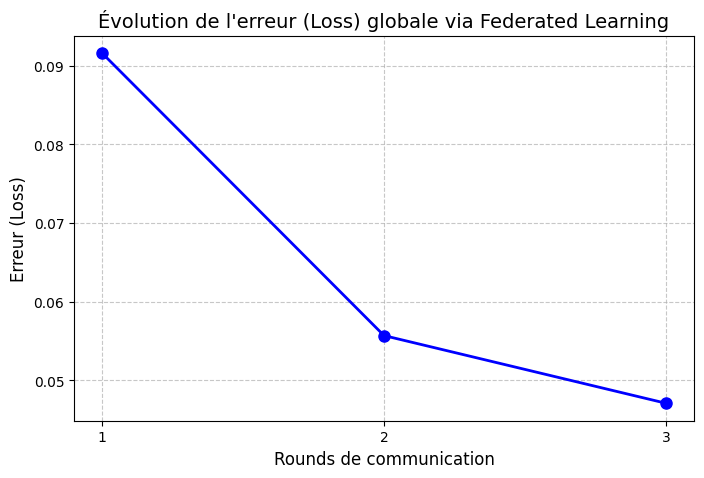

Conclusion pour la présentation : Malgré l'absence de partage de données, la moyenne des matrices a permis de réduire l'erreur du système global de moitié en seulement 3 itérations.


In [ ]:
import matplotlib.pyplot as plt

# Les valeurs extraites de ton journal Flower
rounds = [1, 2, 3]
losses = [0.0916, 0.0557, 0.0471]

plt.figure(figsize=(8, 5))
plt.plot(rounds, losses, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title("Évolution de l'erreur (Loss) globale via Federated Learning", fontsize=14)
plt.xlabel("Rounds de communication", fontsize=12)
plt.ylabel("Erreur (Loss)", fontsize=12)
plt.xticks(rounds)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("Conclusion pour la présentation : Malgré l'absence de partage de données, la moyenne des matrices a permis de réduire l'erreur du système global de moitié en seulement 3 itérations.")

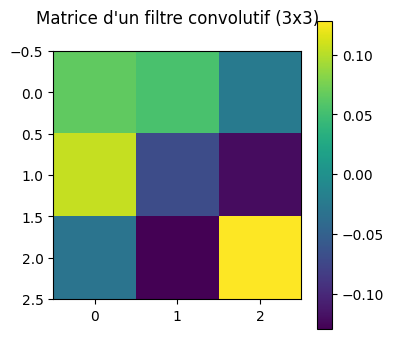


Valeurs exactes de cette matrice (ce qui transite sur le réseau) :
[[ 0.065  0.054 -0.024]
 [ 0.106 -0.07  -0.122]
 [-0.03  -0.13   0.128]]

Argument pour le projet : Cette matrice est une 'boîte noire'. Impossible pour un ingénieur de comprendre quelle règle métier l'IA a apprise en regardant ces chiffres.


In [ ]:
# On extrait les poids de la première couche (Conv2D) de notre modèle de test
poids_couche_1, biais_couche_1 = dummy_model.layers[0].get_weights()

# Le format de Conv2D est (hauteur_filtre, largeur_filtre, canaux_entree, filtres_sortie)
# On sélectionne le tout premier filtre (3x3 pixels)
premier_filtre = poids_couche_1[:, :, 0, 0]

plt.figure(figsize=(4, 4))
# Utilisation de imshow au lieu de matshow pour éviter l'erreur de figure
plt.imshow(premier_filtre, cmap='viridis')
plt.colorbar()
plt.title("Matrice d'un filtre convolutif (3x3)", pad=20)
plt.show()

print("\nValeurs exactes de cette matrice (ce qui transite sur le réseau) :")
print(np.round(premier_filtre, 3))
print("\nArgument pour le projet : Cette matrice est une 'boîte noire'. Impossible pour un ingénieur de comprendre quelle règle métier l'IA a apprise en regardant ces chiffres.")

--- 1. ENTRAÎNEMENT LOCAL ISOLÉ ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/core.py:171: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  return np.array(x)


--- 2. AGRÉGATION SERVEUR (FedAvg) ---
--- 3. MISE À JOUR ET PRÉDICTION CROISÉE ---


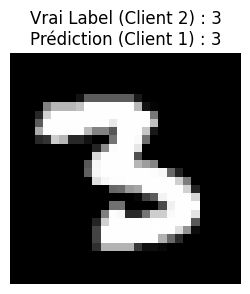

✅ SUCCÈS : Le Client 1 a correctement identifié l'image du Client 2 grâce aux poids partagés via le serveur !


In [ ]:
import random

print("--- 1. ENTRAÎNEMENT LOCAL ISOLÉ ---")
# On crée deux modèles vierges
modele_client1 = create_model()
modele_client2 = create_model()

# Le Client 1 s'entraîne UNIQUEMENT sur ses données
modele_client1.fit(x_train_client1, y_train_client1, epochs=1, batch_size=32, verbose=0)
# Le Client 2 s'entraîne UNIQUEMENT sur les siennes
modele_client2.fit(x_train_client2, y_train_client2, epochs=1, batch_size=32, verbose=0)

print("--- 2. AGRÉGATION SERVEUR (FedAvg) ---")
poids_c1 = modele_client1.get_weights()
poids_c2 = modele_client2.get_weights()

# Le serveur calcule la moyenne mathématique des deux matrices
poids_moyennes = []
for p1, p2 in zip(poids_c1, poids_c2):
    poids_moyennes.append((p1 + p2) / 2.0)

print("--- 3. MISE À JOUR ET PRÉDICTION CROISÉE ---")
# Le Client 1 reçoit la matrice moyenne et met à jour son cerveau
modele_client1.set_weights(poids_moyennes)

# On sélectionne une image au hasard dans le jeu de données strictement privé du Client 2
index_aleatoire = random.randint(0, len(x_train_client2) - 1)
image_secrete = x_train_client2[index_aleatoire]
label_secret = y_train_client2[index_aleatoire]

# Le Client 1 tente de prédire cette image qu'il n'a jamais vue, ni pendant son entraînement, ni dans la base de données
prediction = modele_client1.predict(np.expand_dims(image_secrete, axis=0), verbose=0)
chiffre_predit = np.argmax(prediction)

# Affichage de l'image secrète
plt.figure(figsize=(3, 3))
plt.imshow(image_secrete.squeeze(), cmap='gray')
plt.title(f"Vrai Label (Client 2) : {label_secret}\nPrédiction (Client 1) : {chiffre_predit}")
plt.axis('off')
plt.show()

if label_secret == chiffre_predit:
    print("✅ SUCCÈS : Le Client 1 a correctement identifié l'image du Client 2 grâce aux poids partagés via le serveur !")
else:
    print("❌ ÉCHEC : Le modèle a besoin de plus de rounds d'apprentissage fédéré pour être précis.")